In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
label_map = {
    "2D":"Localization\nScore",
    "ps_association":"Variable Star\nAssociation",
    "MPC":"SSO Association",
    "agn_association":"AGN Association",
    "host_association":"Host Galaxy\nAssociation",
    "distance_score":"Distance Score",
    "phot_kn_scorer":r"$\mathtt{KilonovaSCORER}$"+"\nPhot. Score",
    "phot_metric_based":"Metric Based\nPhot. Score"
}

In [3]:
df = pd.read_json("time-benchmark-result.json")

cols_metric = list(set(df.columns) - {"ec_id", "total_time", "phot_kn_scorer"})
cols_rubin = list(set(df.columns) - {"ec_id", "total_time", "phot_kn_scorer", "MPC"})
cols_kn = list(set(df.columns) - {"ec_id", "total_time", "phot_metric_based"})

df["total_metric"] = df[cols_metric].sum(axis=1)
df["total_kn"] = df[cols_kn].sum(axis=1)
df["total_rubin"] = df[cols_rubin].sum(axis=1)
df.loc[pd.isna(df.phot_kn_scorer), "total_kn"] = np.nan

cols = list(set(df.columns) - {"ec_id", "total_time", "total_metric", "total_kn", "total_rubin"})


df

,2D,ps_association,MPC,agn_association,host_association,distance_score,phot_kn_scorer,phot_metric_based,ec_id,total_time,total_metric,total_kn,total_rubin
0,0.117298,0.225776,0.032715,0.037657,0.298434,0.045741,NaN,0.095504,2718,0.908543,0.853125,NaN,0.820409
1,0.040189,0.014297,0.020599,0.024406,0.238566,0.047166,9.940836,0.100527,2708,10.430826,0.485749,10.326059,0.465150
2,0.021122,0.012260,0.010652,0.018824,0.244732,0.042397,5.090734,0.149470,2701,5.593038,0.499458,5.440721,0.488806
3,0.019539,0.011775,13.677949,0.022975,0.172068,0.040934,3.406486,0.086525,2728,17.440687,14.031765,17.351725,0.353816
4,0.031468,0.012368,0.018963,0.021532,0.236416,0.031875,7.506570,0.126618,2703,7.989967,0.479239,7.859191,0.460276
...,...,...,...,...,...,...,...,...,...,...,...,...,...
451,0.024461,0.011890,12.982362,0.120445,0.679860,0.047170,1.140584,0.081590,4299,15.092790,13.947779,15.006773,0.965417
452,0.024240,0.011369,0.018024,0.125253,0.887977,0.027744,2.821087,0.099642,4300,4.018862,1.194248,3.915694,1.176225
453,0.037343,0.014668,0.020735,0.132483,0.885962,0.026821,2.623219,0.426923,4301,4.170495,1.544935,3.741230,1.524200
454,0.019536,0.010213,0.016992,0.121057,0.614037,0.029368,8.235400,0.087331,4302,9.136530,0.898534,9.046603,0.881542


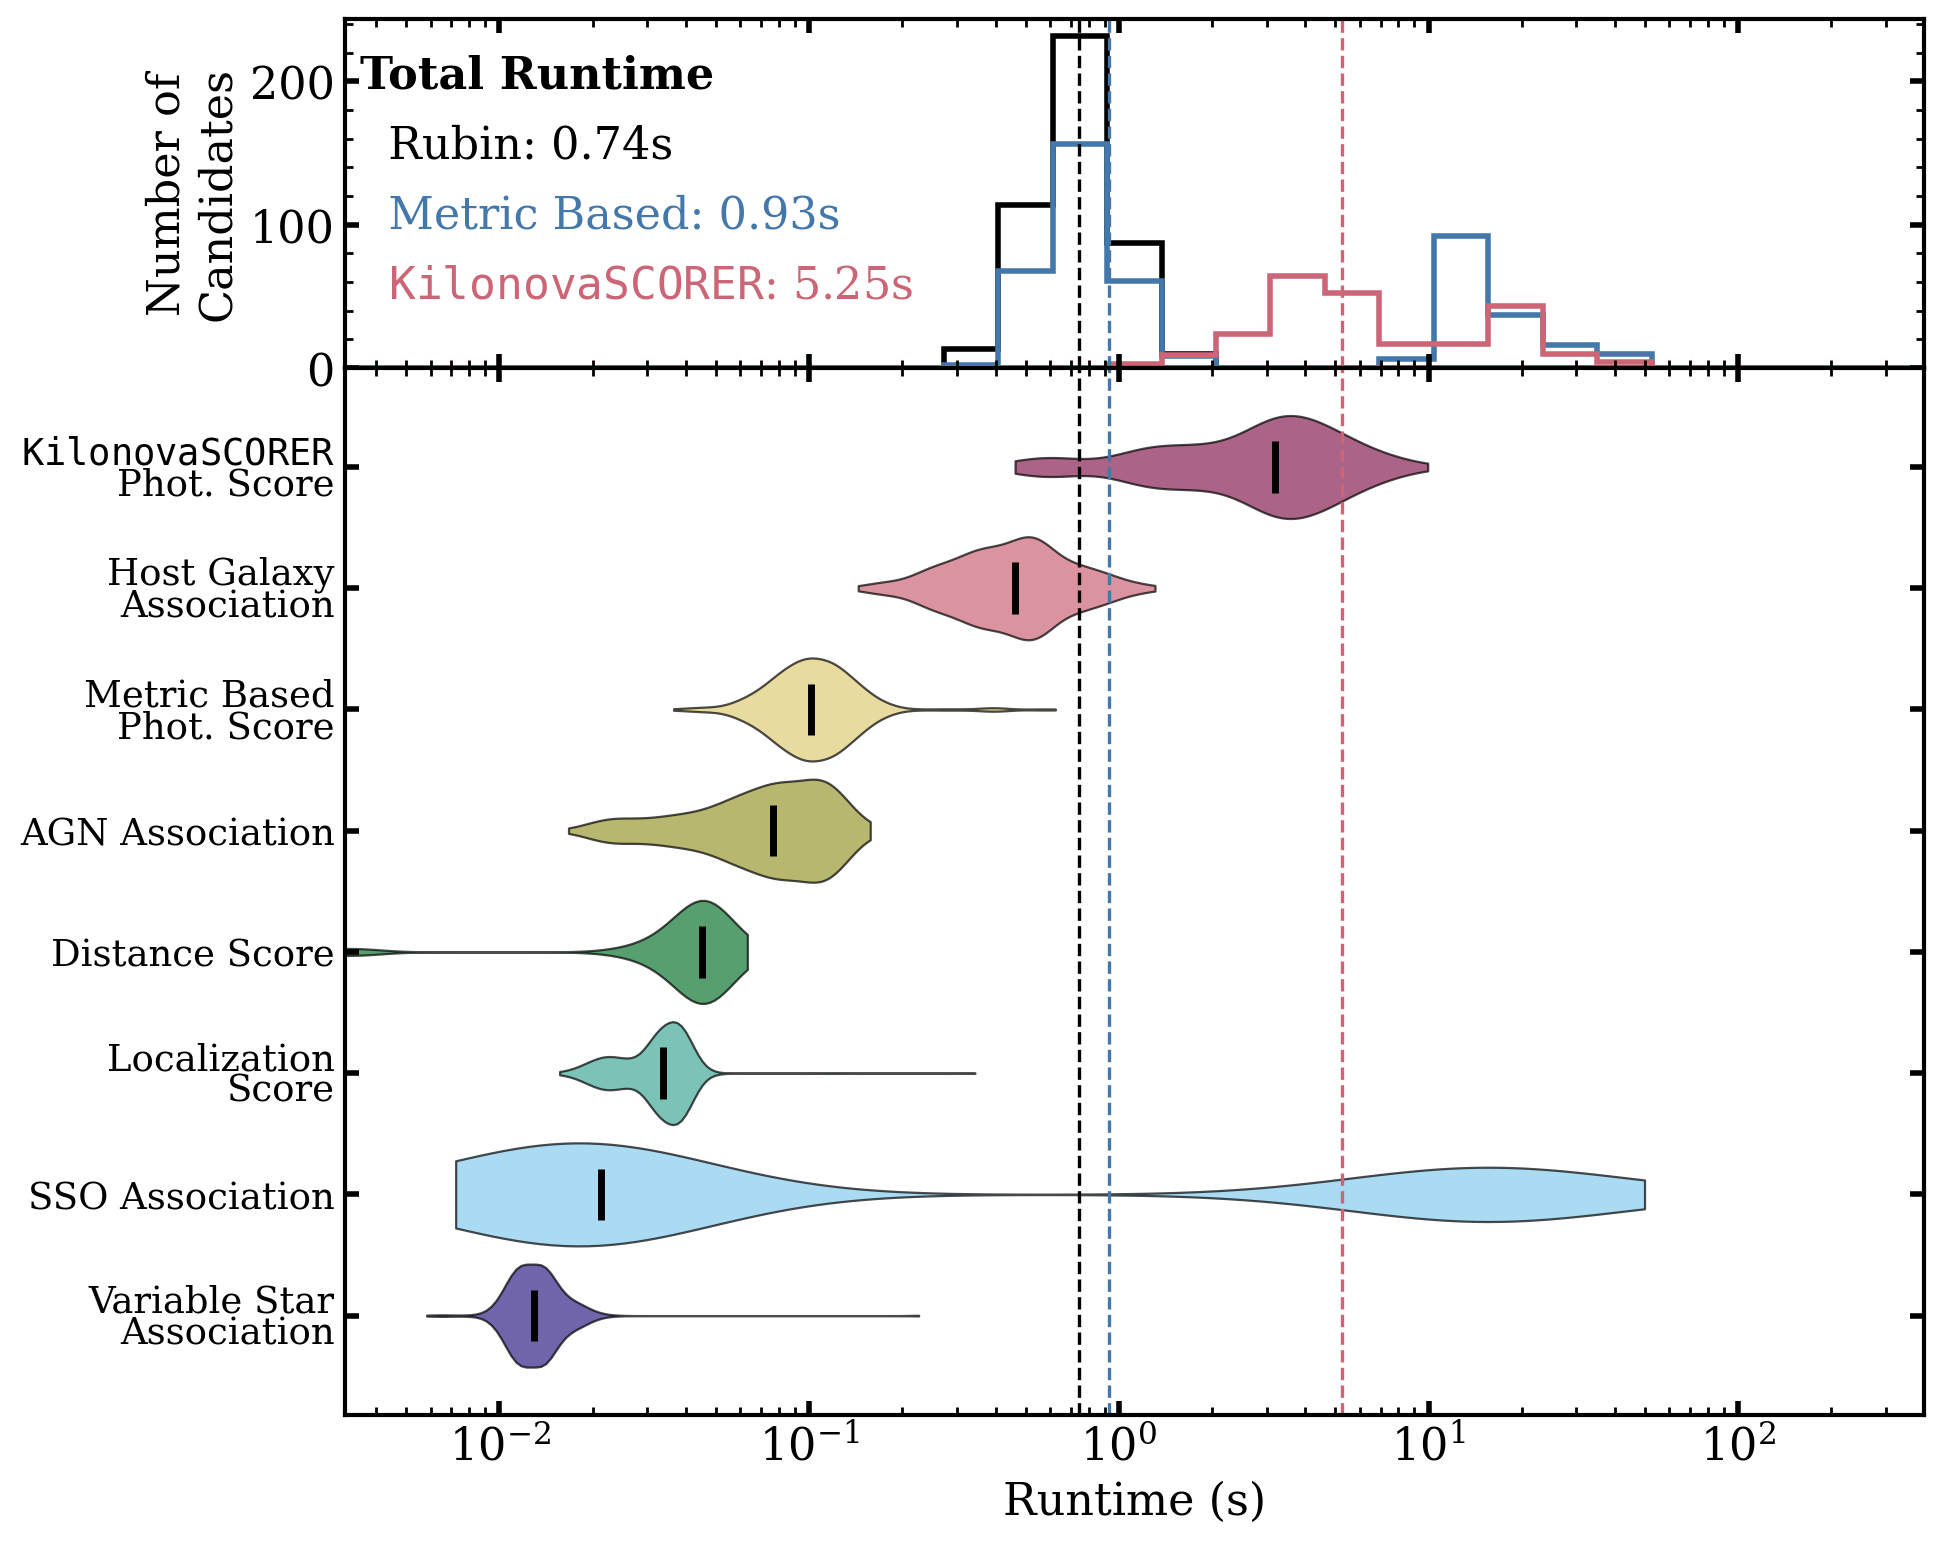

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# Steps sorted by median runtime (fastest at bottom)
step_cols = sorted(cols, key=lambda c: df[c].median())

# Work in log10 space so the violin KDEs are computed on a log scale
log_steps = [np.log10(df[c].dropna()) for c in step_cols]


log_total_metric = np.log10(df["total_metric"].dropna())
log_total_kn = np.log10(df["total_kn"].dropna())
log_total_rubin = np.log10(df["total_rubin"].dropna())


fig, (ax_hist, ax_vio) = plt.subplots(
    2, 1, figsize=(10, 8), sharex=True,
    gridspec_kw={"height_ratios": [1, 3], "hspace": 0},
)

# histogram of total runtimes
metric_color = "#4477AA"   # Paul Tol colorblind-safe blue
kn_color     = "#CC6677"   # Paul Tol colorblind-safe rose
bins = np.linspace(-2.5, 2.6, 30)
ax_hist.text(0.01, 0.9, "Total Runtime", fontweight="bold", transform=ax_hist.transAxes, ha="left", va="top", color="k")
for y, log_total, label, c in zip([0.7, 0.5,0.3], [log_total_rubin, log_total_metric, log_total_kn], ["  Rubin", "  Metric Based", r"  $\mathtt{KilonovaSCORER}$"], ["k", metric_color, kn_color]):
    ax_hist.hist(log_total, bins=bins, histtype="stepfilled",
                 facecolor="none", edgecolor=c, lw=2)

    # Median total_time as a reference line through both panels
    for ax in (ax_hist, ax_vio):
        ax.axvline(log_total.median(), color=c, ls="--", lw=1.2)

    ax_hist.text(0.01, y, f"{label}: {10**log_total.median():.2f}s", transform=ax_hist.transAxes,
             ha="left", va="top", color=c)


ax_hist.set_ylabel("Number of\nCandidates")

# Violin plot of runtime for each individual step
pos = np.arange(len(step_cols))
parts = ax_vio.violinplot(log_steps, positions=pos, orientation="horizontal",
                          widths=0.85, showmedians=True, showextrema=False)

# color in the violin plot
colors = ["#332288", "#88CCEE", "#44AA99", "#117733",
             "#999933", "#DDCC77", "#CC6677", "#882255"]#plt.cm.magma(np.linspace(0, 0.9, len(step_cols)))
for body, col in zip(parts["bodies"], colors):
    body.set_facecolor(col)
    body.set_edgecolor("k")
    body.set_linewidth(0.8)
    body.set_alpha(0.7)
parts["cmedians"].set_color("k")

pretty_names = [label_map[ll] for ll in step_cols]
ax_vio.set_yticks(pos, pretty_names)
ax_vio.set_xlabel("Runtime (s)")



# --- Label log10 positions as 10^n ---
ax_vio.set_xlim(-2.5, 2.6)
ax_vio.xaxis.set_major_locator(FixedLocator(range(-2, 3)))
ax_vio.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(x)}}}$"))
minor = [np.log10(m * 10.0**k) for k in range(-3, 3) for m in range(2, 10)]
ax_vio.xaxis.set_minor_locator(FixedLocator(minor))

from matplotlib.ticker import NullLocator

# No tick marks on the category axis (minor or major, either side)
ax_vio.yaxis.set_minor_locator(NullLocator())
# ax_vio.tick_params(axis="y", which="both", left=False, right=False, pad=4)

# Tighter two-line labels (or make them single-line and drop this)
for t in ax_vio.get_yticklabels():
    t.set_linespacing(0.85)
    t.set_fontsize("small")

fig.savefig("runtime-analysis.png", dpi=300)

In [5]:
quantiles = [0.16, 0.5, 0.75, 0.84]

df.total_metric.quantile(quantiles), df.total_kn.quantile(quantiles), df.total_rubin.quantile(quantiles)

(0.16     0.615906
 0.50     0.928583
 0.75    13.850764
 0.84    14.948406
 Name: total_metric, dtype: float64,
 0.16     3.156952
 0.50     5.247103
 0.75    15.118294
 0.84    16.983772
 Name: total_kn, dtype: float64,
 0.16    0.522935
 0.50    0.741465
 0.75    0.878614
 0.84    0.993267
 Name: total_rubin, dtype: float64)

In [15]:
quantiles = [0.16, 0.5, 0.75, 0.97]
df.host_association.quantile(quantiles)

0.16    0.290058
0.50    0.463834
0.75    0.585891
0.97    0.976169
Name: host_association, dtype: float64

In [16]:
nnodes = 64
time_per_cand = df.total_rubin.median()

time_per_cand/nnodes

0.011585393920540768